In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC

from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Set random seed for reproducibility
np.random.seed(42)

In [3]:
# Read dataset
df = pd.read_csv("emails.csv", encoding="latin-1")

# Remove completely empty columns
df.dropna(axis=1, how="all", inplace=True)

print("First Five Records:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nAvailable Columns:")
print(list(df.columns))

First Five Records:
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]

Dataset Shape:
(5172, 3002)

Dataset Info

In [5]:
# Automatically identify target column
target_candidates = [
    "label",
    "category",
    "v1",
    "spam",
    "target",
    "class",
    "is_spam"
]

target_column = None

for col in df.columns:

    if col.strip().lower() in target_candidates:
        target_column = col
        break

# Ask user if target column is not identified
if target_column is None:

    print("\nAvailable Columns:", list(df.columns))

    target_column = input("Enter target column name: ").strip()

    if target_column not in df.columns:
        raise ValueError("Target column not found!")
        # Automatically identify email text column
text_candidates = [
    "message",
    "v2",
    "text",
    "emailtext",
    "email_text",
    "email",
    "content",
    "body",
    "mail"
]

text_column = None

for col in df.columns:

    if col.strip().lower() in text_candidates:
        if col != target_column:
            text_column = col
            break

# Ask user if text column is not identified
if text_column is None:

    print("\nAvailable Columns:", list(df.columns))

    text_column = input("Enter email text column name: ").strip()

    if text_column not in df.columns or text_column == target_column:
        raise ValueError("Invalid email text column!")

print("\nSelected Target Column:", target_column)
print("Selected Email Text Column:", text_column)




Selected Target Column: spam
Selected Email Text Column: message


In [6]:
# Select required columns
df = df[[text_column, target_column]].copy()

# Rename columns for simplicity
df.columns = ["email", "label"]

# Remove missing values
df.dropna(inplace=True)

# Convert email text into string
df["email"] = df["email"].astype(str)

# Remove unnecessary spaces
df["email"] = df["email"].str.strip()

# Remove empty email messages
df = df[df["email"] != ""]

# Remove duplicate records
df.drop_duplicates(inplace=True)

print("\nDataset After Preprocessing:")
print(df.head())

print("\nDataset Shape After Cleaning:")
print(df.shape)



Dataset After Preprocessing:
    email  label
0       0      0
79      2      0
95      1      0
149     0      1
244     3      0

Dataset Shape After Cleaning:
(25, 2)


In [7]:
def convert_label(value):

    value = str(value).strip().lower()

    value = value.replace("_", " ").replace("-", " ")

    # Normal / Not Spam
    if value in [
        "ham",
        "not spam",
        "normal",
        "legitimate",
        "0",
        "0.0",
        "false",
        "no"
    ]:
        return 0

    # Abnormal / Spam
    elif value in [
        "spam",
        "abnormal",
        "junk",
        "1",
        "1.0",
        "true",
        "yes"
    ]:
        return 1

    else:
        return np.nan


# Apply binary label conversion
df["label"] = df["label"].apply(convert_label)

# Remove records with unknown labels
df.dropna(subset=["label"], inplace=True)

df["label"] = df["label"].astype(int)

if df["label"].nunique() != 2:
    raise ValueError(
        "Dataset must contain both Spam and Not Spam classes."
    )

print("\nBinary Label Conversion Completed!")

print("\nLabel Mapping:")
print("0 = Normal (Not Spam)")
print("1 = Abnormal (Spam)")

print("\nClass Distribution:")
print(df["label"].value_counts())

print("\nClass Distribution Percentage:")
print(df["label"].value_counts(normalize=True) * 100)


Binary Label Conversion Completed!

Label Mapping:
0 = Normal (Not Spam)
1 = Abnormal (Spam)

Class Distribution:
label
0    14
1     5
Name: count, dtype: int64

Class Distribution Percentage:
label
0    73.684211
1    26.315789
Name: proportion, dtype: float64


In [8]:
X = df["email"]

y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)

print("Testing Data Shape:", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())




Training Data Shape: (15,)
Testing Data Shape: (4,)

Training Class Distribution:
label
0    11
1     4
Name: count, dtype: int64


In [9]:
# Create TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

# Fit on training text only
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing text using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

print("\nTF-IDF Transformation Completed!")

print("\nTraining TF-IDF Shape:")
print(X_train_tfidf.shape)

print("\nTesting TF-IDF Shape:")
print(X_test_tfidf.shape)



TF-IDF Transformation Completed!

Training TF-IDF Shape:
(15, 3)

Testing TF-IDF Shape:
(4, 3)


In [10]:
# Select K value
k_input = input("\nEnter K value for KNN (Press Enter for 5): ")

if k_input.strip() == "":
    k = 5
else:
    k = int(k_input)

if k < 1 or k > len(X_train):
    raise ValueError("Invalid K value!")

# Create KNN classifier
knn = KNeighborsClassifier(
    n_neighbors=k,
    metric="cosine",
    algorithm="brute",
    weights="distance"
)

# Train KNN model
knn.fit(X_train_tfidf, y_train)

print("\nKNN Model Trained Successfully!")

# Predict testing data
knn_predictions = knn.predict(X_test_tfidf)

print("\nFirst 10 KNN Predictions:")
print(knn_predictions[:10])



Enter K value for KNN (Press Enter for 5):  5



KNN Model Trained Successfully!

First 10 KNN Predictions:
[0 0 0 0]


In [11]:
# Create Linear SVM classifier
svm = LinearSVC(
    C=1.0,
    max_iter=5000,
    random_state=42
)

# Train SVM model
svm.fit(X_train_tfidf, y_train)

print("\nSVM Model Trained Successfully!")

# Predict testing data
svm_predictions = svm.predict(X_test_tfidf)

print("\nFirst 10 SVM Predictions:")
print(svm_predictions[:10])



SVM Model Trained Successfully!

First 10 SVM Predictions:
[0 0 0 0]


In [12]:
knn_accuracy = accuracy_score(
    y_test,
    knn_predictions
)

knn_error = 1 - knn_accuracy

knn_precision = precision_score(
    y_test,
    knn_predictions,
    pos_label=1,
    zero_division=0
)

knn_recall = recall_score(
    y_test,
    knn_predictions,
    pos_label=1,
    zero_division=0
)

knn_f1 = f1_score(
    y_test,
    knn_predictions,
    pos_label=1,
    zero_division=0
)

print("\nKNN PERFORMANCE:")

print("Accuracy:", round(knn_accuracy, 4))

print("Error Rate:", round(knn_error, 4))

print("Precision:", round(knn_precision, 4))

print("Recall:", round(knn_recall, 4))

print("F1 Score:", round(knn_f1, 4))




KNN PERFORMANCE:
Accuracy: 0.75
Error Rate: 0.25
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


In [13]:
knn_cm = confusion_matrix(
    y_test,
    knn_predictions,
    labels=[0, 1]
)

print("\nKNN Confusion Matrix:")
print(knn_cm)

tn, fp, fn, tp = knn_cm.ravel()

print("\nTrue Negative:", tn)

print("False Positive:", fp)

print("False Negative:", fn)

print("True Positive:", tp)


KNN Confusion Matrix:
[[3 0]
 [1 0]]

True Negative: 3
False Positive: 0
False Negative: 1
True Positive: 0


In [14]:
svm_accuracy = accuracy_score(
    y_test,
    svm_predictions
)

svm_error = 1 - svm_accuracy

svm_precision = precision_score(
    y_test,
    svm_predictions,
    pos_label=1,
    zero_division=0
)

svm_recall = recall_score(
    y_test,
    svm_predictions,
    pos_label=1,
    zero_division=0
)

svm_f1 = f1_score(
    y_test,
    svm_predictions,
    pos_label=1,
    zero_division=0
)

print("\nSVM PERFORMANCE:")

print("Accuracy:", round(svm_accuracy, 4))

print("Error Rate:", round(svm_error, 4))

print("Precision:", round(svm_precision, 4))

print("Recall:", round(svm_recall, 4))

print("F1 Score:", round(svm_f1, 4))



SVM PERFORMANCE:
Accuracy: 0.75
Error Rate: 0.25
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


In [15]:
svm_cm = confusion_matrix(
    y_test,
    svm_predictions,
    labels=[0, 1]
)

print("\nSVM Confusion Matrix:")
print(svm_cm)

tn, fp, fn, tp = svm_cm.ravel()

print("\nTrue Negative:", tn)

print("False Positive:", fp)

print("False Negative:", fn)

print("True Positive:", tp)



SVM Confusion Matrix:
[[3 0]
 [1 0]]

True Negative: 3
False Positive: 0
False Negative: 1
True Positive: 0


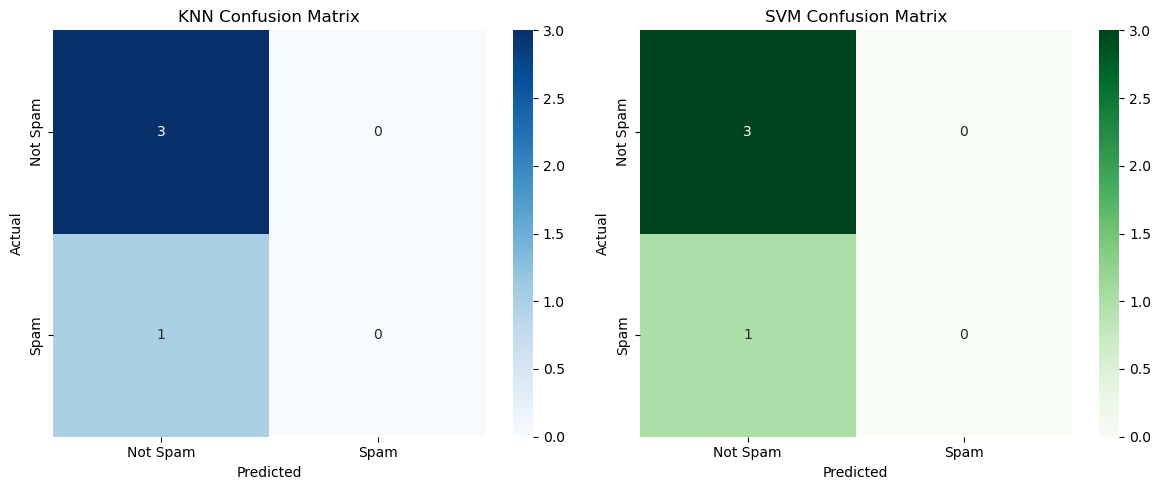

In [16]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

sns.heatmap(
    knn_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Spam", "Spam"],
    yticklabels=["Not Spam", "Spam"]
)

plt.title("KNN Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")


plt.subplot(1, 2, 2)

sns.heatmap(
    svm_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Not Spam", "Spam"],
    yticklabels=["Not Spam", "Spam"]
)

plt.title("SVM Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.tight_layout()

plt.show()


In [17]:
print("\nKNN CLASSIFICATION REPORT:")

print(
    classification_report(
        y_test,
        knn_predictions,
        labels=[0, 1],
        target_names=["Not Spam", "Spam"],
        zero_division=0
    )
)


print("\nSVM CLASSIFICATION REPORT:")

print(
    classification_report(
        y_test,
        svm_predictions,
        labels=[0, 1],
        target_names=["Not Spam", "Spam"],
        zero_division=0
    )
)


KNN CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    Not Spam       0.75      1.00      0.86         3
        Spam       0.00      0.00      0.00         1

    accuracy                           0.75         4
   macro avg       0.38      0.50      0.43         4
weighted avg       0.56      0.75      0.64         4


SVM CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    Not Spam       0.75      1.00      0.86         3
        Spam       0.00      0.00      0.00         1

    accuracy                           0.75         4
   macro avg       0.38      0.50      0.43         4
weighted avg       0.56      0.75      0.64         4



In [18]:
comparison = pd.DataFrame({

    "Evaluation Metric": [
        "Accuracy",
        "Error Rate",
        "Precision",
        "Recall",
        "F1 Score"
    ],

    "KNN": [
        knn_accuracy,
        knn_error,
        knn_precision,
        knn_recall,
        knn_f1
    ],

    "SVM": [
        svm_accuracy,
        svm_error,
        svm_precision,
        svm_recall,
        svm_f1
    ]

})

print("\nMODEL PERFORMANCE COMPARISON:")

print(comparison.to_string(index=False))

# Identify the better model using F1 Score
if knn_f1 > svm_f1:

    print("\nBetter Performing Model: KNN")

elif svm_f1 > knn_f1:

    print("\nBetter Performing Model: SVM")

else:

    print("\nBoth models have equal F1 Scores.")


MODEL PERFORMANCE COMPARISON:
Evaluation Metric  KNN  SVM
         Accuracy 0.75 0.75
       Error Rate 0.25 0.25
        Precision 0.00 0.00
           Recall 0.00 0.00
         F1 Score 0.00 0.00

Both models have equal F1 Scores.


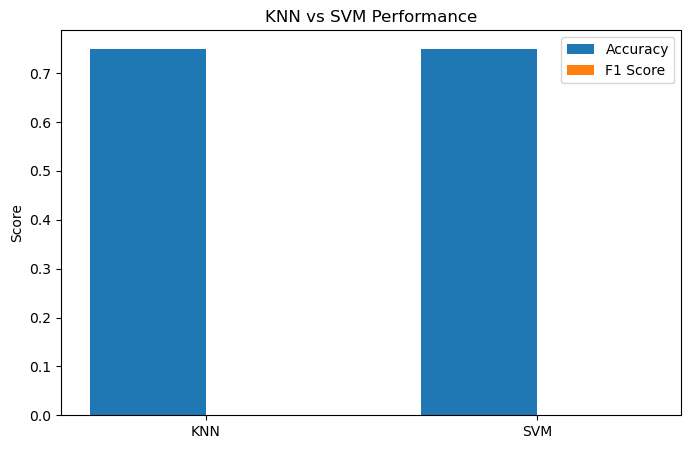

In [19]:
models = ["KNN", "SVM"]

accuracies = [knn_accuracy, svm_accuracy]

f1_scores = [knn_f1, svm_f1]

x = np.arange(len(models))

width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    accuracies,
    width,
    label="Accuracy"
)

plt.bar(
    x + width / 2,
    f1_scores,
    width,
    label="F1 Score"
)

plt.xticks(x, models)

plt.ylabel("Score")

plt.title("KNN vs SVM Performance")

plt.legend()

plt.show()



In [23]:
new_email = input("Enter an email message to classify: ")

if new_email.strip():

    new_email_tfidf = tfidf.transform([new_email])

    knn_result = knn.predict(new_email_tfidf)[0]
    svm_result = svm.predict(new_email_tfidf)[0]

    print("\nKNN Prediction:")
    print("Abnormal State: SPAM" if knn_result == 1
          else "Normal State: NOT SPAM")

    print("\nSVM Prediction:")
    print("Abnormal State: SPAM" if svm_result == 1
          else "Normal State: NOT SPAM")

else:
    print("Please enter a valid email!")
    

Enter an email message to classify:  Congratulations! You have won a $10,000 lottery. Click here to claim your prize now!



KNN Prediction:
Normal State: NOT SPAM

SVM Prediction:
Normal State: NOT SPAM
